# 상태 기록과 다른 분기 재실행

**이 노트북에서 할 일**

1. 끝난 실행의 체크포인트 목록에서, 돌아갈 체크포인트 하나를 고릅니다.
2. 고른 체크포인트에 할인 백분율을 고쳐 넣고, 그 자리부터 다시 실행해 새 가지를 만듭니다.
3. 원래 가지와 새 가지의 가격이 함께 남는지, 멈춤 표시에서 다시 멈추는지 봅니다.

**준비물** — 이 노트북은 모델을 부르지 않습니다.
모델 요청은 0번이고, API 키 없이 실행합니다.
사람의 답은 우리가 셀에 적어 넣는 값(`"approve"`)입니다.
실제 서비스라면 화면에서 사람이 고른 값을 같은 자리에 넣습니다.
매번 같은 값을 내는 우리 노드로, 가격과 노드가 실행된 차례를 봅니다.

체크포인트는 메모리에만 저장하고, 파일은 하나도 쓰지 않습니다.
그래도 01절과 같은 모양으로 빈 임시 폴더를 만들고, 마지막 셀에서 그 폴더가 비어 있는지 봅니다.
읽어 오는 자료 파일은 없습니다.
걸린 시간은 재지 않았습니다.

**기준 버전** — 첫 셀에서 패키지 둘을 설치합니다.
그래프는 langgraph 1.2.11, 체크포인터는 langgraph-checkpoint 4.2.0에 들어 있습니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 실행하지 않았습니다.
설치 셀에 걸리는 시간은 네트워크에 따라 달라집니다.

**강의와 실습 범위** — 강의 시간에는 2~6절을 읽습니다.
체크포인트를 고르고, 값을 고쳐 넣어 새 가지를 만드는 자리입니다.
7~9절은 값을 바꾸지 않고 다시 실행하거나 값을 바꿔 보는 자리이고, 실습 시간에 실행합니다.
셀 하나만 다시 실행하면 같은 스레드에 체크포인트가 더해지고 실행 기록 목록도 늘어, 값이 달라집니다.
처음 값으로 다시 보려면 1절 임시 폴더 셀부터 다시 실행합니다.

실습 폴더 `labs/part6/ch24-human-in-the-loop`에서 `uv sync --locked`를 실행합니다.
그다음 `notebooks/` 폴더의 이 노트북을 열고, 실습 폴더의 `.venv` 커널을 고릅니다.
첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![위에 회색 상자 하나가 있고 아래에 칸 둘이 나란히 놓인 그림입니다. 회색 상자에는 고른 체크포인트 두 가지 같음, 단계 1 만든 자리 loop, 다음 노드 discount, 기본 가격 10000 할인 10이 적혀 있고, 두 칸으로 화살표가 갑니다. 칸 원래 가지 첫 실행에는 노란 상자 단계 2 loop 질문 값 최종 가격 9000 아래에 노란 상자 단계 3 loop 최종 가격 9000 approve가 있습니다. 칸 새 가지 값 고쳐 넣기에는 초록 상자 할인 20을 update_state로 넣음 아래로 노란 상자 셋이 차례로 이어집니다. 단계 2 만든 자리 update 할인 20, 단계 3 loop 질문 값 최종 가격 8000, 단계 4 loop 최종 가격 8000 approve인 그림](attachment:03-1-고른-체크포인트에서-이어-붙인-새-가지.png)

위에서 아래로 읽습니다.
맨 위 회색 상자는 두 가지가 함께 딛고 선 체크포인트이고, 노트북 4절에서 고른 단계 1 줄입니다.
칸 안의 노란 상자는 노트북 3절과 6절에서 출력한 체크포인트 줄이고, 초록 상자는 우리가 고쳐 넣은 값입니다.
두 칸 모두 단계 번호가 2부터 이어지지만, 서로 다른 체크포인트입니다.
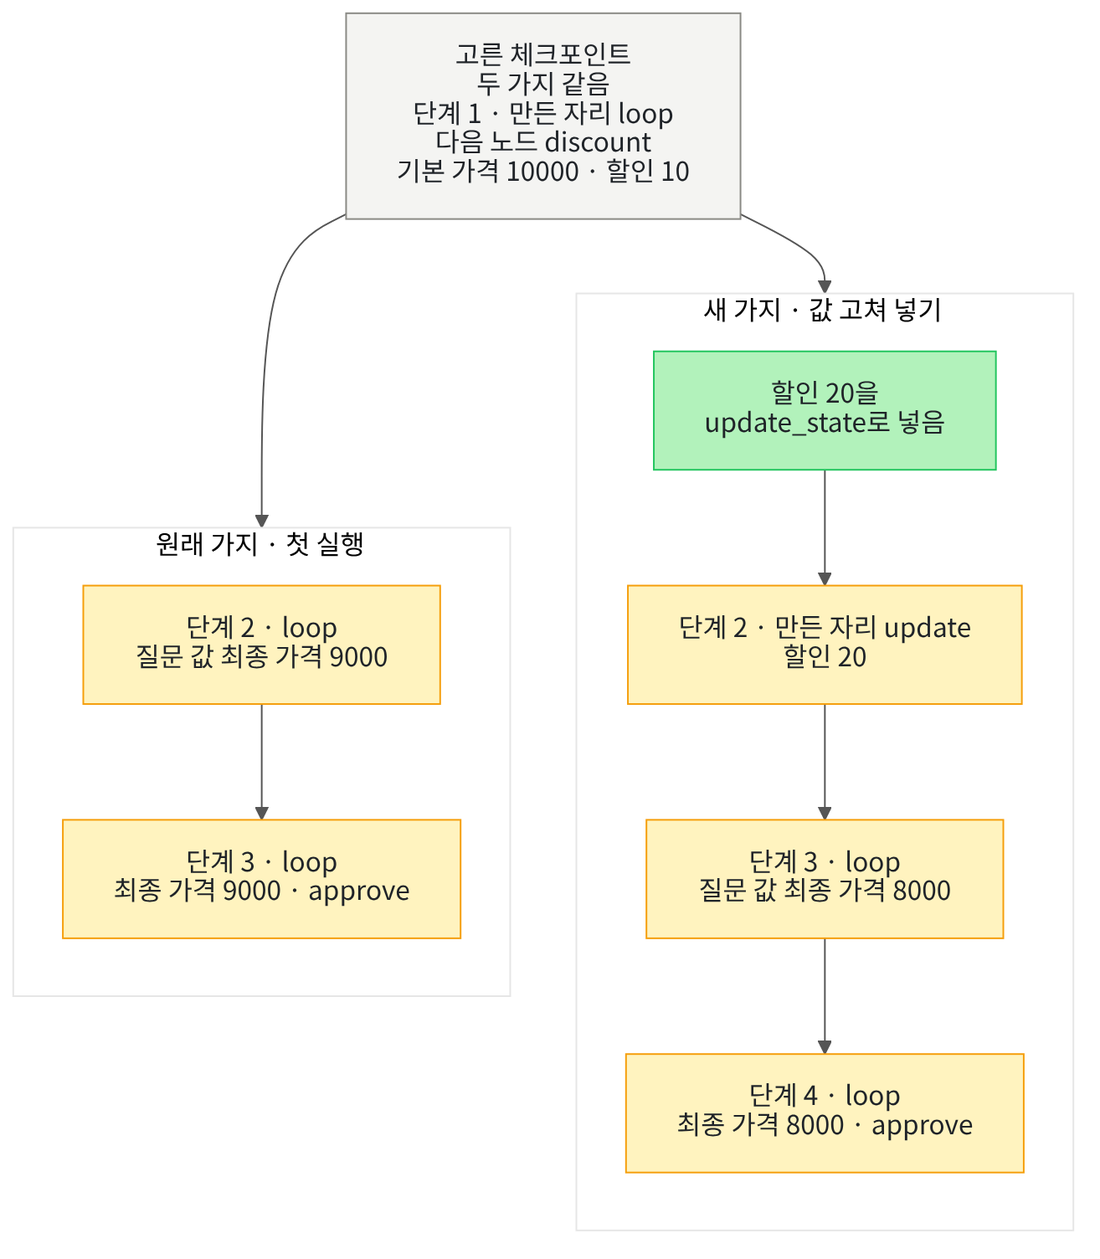

## 1. 준비

02절까지는 멈춘 실행을 가장 최근 체크포인트에서 이어 갔습니다.
이 절에서는 이미 끝난 실행의 지난 체크포인트로 돌아가, 값을 바꿔 그 자리부터 다시 실행합니다.
절 제목은 지난 체크포인트로 돌아가 값을 바꾸고, 그 자리부터 새 가지로 다시 실행하는 일을 가리킵니다.
본문에서는 제목의 두 말 대신 새 가지와 다시 실행이라고 씁니다.

첫 셀은 01절과 같은 패키지 둘을 설치하고, 설치된 판 번호를 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langgraph==1.2.11" "langgraph-checkpoint==4.2.0"
from importlib.metadata import version

print("langgraph:", version("langgraph"))
print("langgraph-checkpoint:", version("langgraph-checkpoint"))

Note: you may need to restart the kernel to use updated packages.
langgraph: 1.2.11
langgraph-checkpoint: 4.2.0


**결과 읽기** — 출력 줄 `langgraph: 1.2.11`과 `langgraph-checkpoint: 4.2.0`이 보입니다.
두 판 모두 실습 폴더 잠금과 같은 판입니다.
이 노트북의 출력은 2026-09-25에 이 판으로 실행한 결과입니다.

다음 셀은 이 절에서 쓸 이름을 가져옵니다.
상태 형식과 그래프 이름은 Ch 13 01절, 체크포인터 `InMemorySaver`는 Ch 23 01절과 같습니다.
함수 `interrupt`와 객체 `Command`는 01절에서 가져온 이름 그대로입니다.
마지막 가져오기 줄은 Ch 23 01절에서 배운 함수 `print_history`를 도구 파일 `approval_tools.py`에서 가져옵니다.

In [2]:
# 그래프 이름(Ch 13 01절)·체크포인터(Ch 23 01절)와, 01절에서 쓴 멈춤 표시 이름 둘을 가져옵니다
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import InMemorySaver
# interrupt는 노드를 멈추는 함수, Command는 멈춘 그래프에 사람의 답을 넘길 때 쓰는 객체입니다(01절)
from langgraph.types import Command, interrupt
# Ch 23 01절에서 배운 함수를 도구 파일에서 가져옵니다
from approval_tools import print_history

print("langgraph.types에서 가져온 이름:", "Command, interrupt")
print("도구 파일에서 가져온 함수:", "print_history")

langgraph.types에서 가져온 이름: Command, interrupt
도구 파일에서 가져온 함수: print_history


**결과 읽기** — 출력 줄 `도구 파일에서 가져온 함수: print_history`가 보입니다.

앞에서 배운 함수는 `approval_tools.py`에 모아 두었습니다.
파일을 열면 코드를 볼 수 있습니다.
노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다.
커널이 `notebooks/` 폴더에서 시작해야 이 파일을 가져올 수 있어, 작업 위치를 옮기기 전에 가져왔습니다.
교재 출력을 만든 실행 도구는 이 폴더를 따로 알려 주어, 다른 자리에서 시작해도 가져오기가 되었습니다.

함수 `print_history`는 체크포인트 목록을 받아, 하나마다 한 줄을 출력합니다.
한 줄에는 단계 번호, 만든 자리, 다음 노드, 칸 값을 적습니다.
도구 파일의 이 함수는 Ch 23 01절 노트북의 같은 이름 함수를 글자 그대로 옮긴 것입니다.

다음 셀은 01절처럼 빈 임시 폴더를 만들고, 그 폴더로 작업 위치를 옮깁니다.
이 절은 파일을 쓰지 않지만, 마지막 셀에서 이 폴더가 그대로 비어 있는지 봅니다.
폴더 위치는 컴퓨터마다 달라 출력하지 않고, 폴더 이름의 앞머리만 확인합니다.

In [3]:
# 파일이 생기는지 볼 빈 임시 폴더를 만들고, 그 폴더로 작업 위치를 옮깁니다(Ch 23 01절과 같은 모양)
import os
import tempfile

# mkdtemp()는 운영체제 임시 폴더 안에 새 폴더를 만들고, 그 폴더의 위치를 글로 내놓습니다
practice_folder = tempfile.mkdtemp(prefix="ch24-03-")
# chdir()는 터미널의 cd처럼 현재 작업 폴더를 옮깁니다
os.chdir(practice_folder)
print("임시 폴더 이름에 ch24-03-이 들어 있는가:", "ch24-03-" in practice_folder)
print("현재 작업 폴더의 파일:", os.listdir())

임시 폴더 이름에 ch24-03-이 들어 있는가: True
현재 작업 폴더의 파일: []


**결과 읽기** — 출력 줄 `임시 폴더 이름에 ch24-03-이 들어 있는가: True`로, 이 절의 폴더를 만들었습니다.
출력 줄 `현재 작업 폴더의 파일: []`로, 빈 폴더에서 시작합니다.

## 2. 가격을 계산하고 묻는 그래프

이 절의 그래프는 노드 셋을 한 줄로 잇습니다.
견적 노드 `quote`가 기본 가격을 내고, 할인 노드 `discount`가 최종 가격을 냅니다.
확인 노드 `ask_price`는 01절처럼 최종 가격을 질문 값에 담아 멈춤 표시로 묻습니다.

할인은 백분율을 정수로 두고 계산합니다.
다음 셀은 그 까닭을 봅니다.
할인 33%를 소수 할인율 `0.33`으로 계산한 값과, 정수 `33`으로 계산한 값을 견줍니다.
연산자 `//`는 나눈 몫의 정수 부분만 내놓습니다.

In [4]:
# 할인 33%를 소수 할인율로 계산한 값과, 정수 백분율로 계산한 값을 견줍니다
sample_price = 10000
sample_rate = 0.33
float_price = sample_price * (1 - sample_rate)
print("소수 할인율로 계산한 값:", float_price)
print("int로 소수점 아래를 버린 값:", int(float_price))
# 100은 할인하지 않은 전체(100%)이고, //는 나눈 몫의 정수 부분만 내놓습니다
full_percent = 100
sample_percent = 33
print("정수 백분율로 계산한 값:", sample_price * (full_percent - sample_percent) // full_percent)

소수 할인율로 계산한 값: 6699.999999999999
int로 소수점 아래를 버린 값: 6699
정수 백분율로 계산한 값: 6700


**결과 읽기** — 출력 줄 `소수 할인율로 계산한 값: 6699.999999999999`입니다.
컴퓨터는 소수를 2진수로 담아, 끝자리에 아주 작은 어긋남이 생깁니다.
출력 줄 `int로 소수점 아래를 버린 값: 6699`로, 소수점 아래를 버리면 1원이 모자랍니다.
출력 줄 `정수 백분율로 계산한 값: 6700`은 소수를 거치지 않아 맞게 나왔습니다.
그래서 이 절의 할인 노드는 할인 백분율을 정수 칸에 두고 `//`로 계산합니다.

다음 셀은 이 절의 상태 형식을 만듭니다.
칸 `quantity`는 수량, 칸 `base_price`는 기본 가격, 칸 `percent`는 할인 백분율입니다.
칸 `final_price`는 최종 가격, 칸 `answer`는 사람의 답입니다.
다섯 칸 모두 규칙을 적지 않아, 새 값이 오면 덮어씁니다.
01절 `ApprovalState`·02절 `ReviewState`와 칸이 달라, 이름도 새로 붙였습니다.

In [5]:
# 수량·기본 가격·할인 백분율·최종 가격·사람의 답 칸을 둔 상태 형식을 만듭니다(Ch 13 01절 모양, 다섯 칸 모두 규칙 없음)
class PriceState(TypedDict):
    quantity: int
    base_price: int
    percent: int
    final_price: int
    answer: str

**결과 읽기** — 정의 셀이라 출력이 없습니다.
이 절의 그래프는 이 상태 형식 하나를 씁니다.

다음 셀은 견적 노드입니다.
수량에 한 개 값 2500원을 곱해, 기본 가격을 칸 `base_price`에 냅니다.
02절처럼 노드는 실행될 때마다 자기 이름을 목록 `price_calls`에 적습니다.
이 목록으로 어느 노드가 몇 번 실행되었는지 셉니다.
목록 `price_calls`는 뒤의 컴파일 셀에서 만듭니다.

In [6]:
# 견적 노드: 수량에 한 개 값을 곱해 기본 가격을 칸 base_price에 냅니다
def quote(state):
    # 실행될 때마다 노드 이름을 목록에 적어, 몇 번 실행되었는지 셀 수 있게 합니다(02절 모양)
    price_calls.append("quote")
    # 한 개 값 2500원은 이 절에서 정해 둔 값입니다
    unit_price = 2500
    return {"base_price": unit_price * state["quantity"]}

**결과 읽기** — 정의 셀이라 출력이 없습니다.
노드는 자기 칸 `base_price`만 냅니다.

다음 셀은 할인 노드입니다.
앞에서 본 대로, 기본 가격에 할인하고 남는 백분율을 곱한 뒤 `//`로 100으로 나눕니다.
결과는 원 단위 정수이고, 칸 `final_price`에 냅니다.

In [7]:
# 할인 노드: 기본 가격에서 할인 백분율만큼 뺀 최종 가격을 정수로 계산해 칸 final_price에 냅니다
def discount(state):
    price_calls.append("discount")
    full_percent = 100
    kept_percent = full_percent - state["percent"]
    # 곱한 뒤 //로 나누어, 소수를 거치지 않고 원 단위 정수로 계산합니다
    final_price = state["base_price"] * kept_percent // full_percent
    return {"final_price": final_price}

**결과 읽기** — 정의 셀이라 출력이 없습니다.
기본 가격이 10000원이고 할인이 10이면, 최종 가격은 9000원이 됩니다.

다음 셀은 확인 노드입니다.
01절의 노드처럼 질문 값을 만들어 함수 `interrupt`로 멈추고, 이어 갈 때 받은 답을 칸 `answer`에 냅니다.
질문 값에는 최종 가격과 질문 글을 담습니다.

In [8]:
# 확인 노드: 최종 가격을 질문 값에 담아 멈춤 표시로 묻고, 받은 답을 칸 answer에 냅니다(01절 모양)
def ask_price(state):
    price_calls.append("ask_price")
    question = {"final_price": state["final_price"], "question": "이 가격으로 결제할까요?"}
    # 처음 부를 때 이 줄에서 멈추고, 이어 갈 때는 사람의 답을 내놓습니다
    answer = interrupt(question)
    return {"answer": answer}

**결과 읽기** — 정의 셀이라 출력이 없습니다.
01절에서 본 것처럼, 이어 갈 때 이 노드는 첫 줄부터 다시 실행됩니다.
그래서 이어 갈 때마다 목록에 `ask_price`가 한 번 더 적힙니다.

다음 셀은 노드 셋을 등록하고, 가상 시작점부터 가상 끝점까지 한 줄로 잇습니다.
이 절의 그래프에는 조건부 엣지가 없습니다.

In [9]:
# 노드 셋을 등록하고 START → quote → discount → ask_price → END 차례로 잇습니다
price_builder = StateGraph(PriceState)
price_builder.add_node("quote", quote)
price_builder.add_node("discount", discount)
price_builder.add_node("ask_price", ask_price)
price_builder.add_edge(START, "quote")
price_builder.add_edge("quote", "discount")
price_builder.add_edge("discount", "ask_price")
price_builder.add_edge("ask_price", END)
print("고정 엣지로 적은 수:", len(price_builder.edges))

고정 엣지로 적은 수: 4


**결과 읽기** — 출력 줄 `고정 엣지로 적은 수: 4`입니다.
엣지 넷은 `START` → `quote` → `discount` → `ask_price` → `END` 차례입니다.

다음 셀은 체크포인터를 붙여 컴파일합니다.
체크포인터가 있어야 멈춘 자리와 지난 체크포인트가 남습니다.
노드가 이름을 적을 목록 `price_calls`도 여기서 만듭니다.

In [10]:
# 멈춘 자리와 지난 체크포인트를 저장하도록 체크포인터를 붙여 컴파일합니다
price_graph = price_builder.compile(checkpointer=InMemorySaver())
# 노드가 실행될 때마다 이름을 적을 목록입니다
price_calls = []
print("등록한 노드:", list(price_builder.nodes))
print("실행 기록 목록:", price_calls)

등록한 노드: ['quote', 'discount', 'ask_price']
실행 기록 목록: []


**결과 읽기** — 출력 줄 `등록한 노드: ['quote', 'discount', 'ask_price']`입니다.
출력 줄 `실행 기록 목록: []`로, 목록은 아직 비어 있습니다.

## 3. 첫 실행과 체크포인트 목록

다음 셀은 수량 `4`와 할인 `10`을 넣어 첫 실행을 합니다.
스레드 이름은 `price-2403`입니다.
셀을 실행하기 전 목록의 길이를 적어 두고, 이 셀에서 새로 적힌 이름만 잘라 출력합니다.
실행 전에 예상해 봅니다.
노드 셋이 차례로 실행되고, 확인 노드의 멈춤 표시에서 멈출 것입니다.

In [11]:
# 첫 실행: 수량 4·할인 10을 스레드 price-2403으로 넣고, 멈춘 뒤 실행된 노드와 질문 값을 봅니다
price_config = {"configurable": {"thread_id": "price-2403"}}
first_input = {"quantity": 4, "base_price": 0, "percent": 10, "final_price": 0, "answer": "대기"}
# 실행 전 목록 길이를 적어 두고, 이 셀에서 새로 적힌 이름만 잘라 봅니다
call_count = len(price_calls)
first_result = price_graph.invoke(first_input, price_config)
print("이 셀에서 실행된 노드:", price_calls[call_count:])
print("질문 값:", first_result["__interrupt__"][0].value)

이 셀에서 실행된 노드: ['quote', 'discount', 'ask_price']
질문 값: {'final_price': 9000, 'question': '이 가격으로 결제할까요?'}


**결과 읽기** — 출력 줄 `이 셀에서 실행된 노드: ['quote', 'discount', 'ask_price']`입니다.
출력 줄 `질문 값: {'final_price': 9000, 'question': '이 가격으로 결제할까요?'}`로, 최종 가격을 물으며 멈췄습니다.
기본 가격 10000원에서 10%를 뺀 값입니다.

다음 셀은 사람의 답 `approve`로 이어 갑니다.
실행 전에 예상해 봅니다.
01절처럼 확인 노드만 첫 줄부터 다시 실행되어 답을 받을 것입니다.

In [12]:
# 사람의 답 "approve"로 이어 가고, 이 셀에서 실행된 노드와 결과를 봅니다
call_count = len(price_calls)
first_done = price_graph.invoke(Command(resume="approve"), price_config)
print("이 셀에서 실행된 노드:", price_calls[call_count:])
print("이어 간 뒤 결과:", first_done)

이 셀에서 실행된 노드: ['ask_price']
이어 간 뒤 결과: {'quantity': 4, 'base_price': 10000, 'percent': 10, 'final_price': 9000, 'answer': 'approve'}


**결과 읽기** — 출력 줄 `이 셀에서 실행된 노드: ['ask_price']`로, 확인 노드만 다시 실행되었습니다.
출력 줄 `이어 간 뒤 결과:`의 딕셔너리에는 `'final_price': 9000`과 `'answer': 'approve'`가 있습니다.
첫 실행은 여기서 끝났습니다.

다음 셀은 이 스레드의 체크포인트 목록을 받아, 함수 `print_history`로 한 줄씩 봅니다.
Ch 23 01절처럼 목록은 최신 것부터 놓입니다.

In [13]:
# 스레드 price-2403의 체크포인트 목록을 받아 수를 세고, 한 줄씩 봅니다(목록은 최신 것부터)
first_history = list(price_graph.get_state_history(price_config))
print("체크포인트 수:", len(first_history))
print_history(first_history)
# 노드 셋을 한 번씩 실행하고 한 번 멈춘 우리 그래프의 수라, 실행마다 같아야 합니다
assert len(first_history) == 5, "첫 실행을 마친 뒤 체크포인트는 다섯이어야 합니다"

체크포인트 수: 5
단계 번호 | 만든 자리 | 다음 노드 | 칸 값
3 | loop | () | {'quantity': 4, 'base_price': 10000, 'percent': 10, 'final_price': 9000, 'answer': 'approve'}
2 | loop | ('ask_price',) | {'quantity': 4, 'base_price': 10000, 'percent': 10, 'final_price': 9000, 'answer': '대기'}
1 | loop | ('discount',) | {'quantity': 4, 'base_price': 10000, 'percent': 10, 'final_price': 0, 'answer': '대기'}
0 | loop | ('quote',) | {'quantity': 4, 'base_price': 0, 'percent': 10, 'final_price': 0, 'answer': '대기'}
-1 | input | ('__start__',) | {}


**결과 읽기** — 출력 줄 `체크포인트 수: 5`입니다.
라벨 줄 아래 맨 아래 줄 `-1 | input | ('__start__',) | {}`는 첫 입력을 받은 때의 체크포인트입니다.
그 위 넷은 만든 자리가 `loop`이고, 단계 번호가 0부터 3까지입니다.
단계 1 줄은 다음 노드가 `('discount',)`이고, 칸 `base_price`가 이미 `10000`입니다.
단계 2 줄은 확인 노드에서 멈춘 때이고, 맨 위 단계 3 줄이 첫 실행의 끝입니다.

단계 1 줄은 견적 노드를 마치고 할인 노드를 실행하기 전의 자리입니다.
이 자리로 돌아가면, 기본 가격은 그대로 두고 할인만 다르게 계산해 볼 수 있습니다.

## 4. 돌아갈 체크포인트 고르기

지난 체크포인트에서 다시 실행(Time Travel)은 지난 체크포인트 하나를 골라, 그 자리부터 다시 실행하는 일입니다.
Ch 23에서는 체크포인트를 즉석사진 한 장에 비유했습니다.
도미노 줄이 어디까지 넘어졌는지 찍은 사진을 보고, 그 자리부터 줄을 다시 세우는 것과 같습니다.
이 절 코드에서는 고른 체크포인트의 설정을 `invoke`에 넣는 일이고, 5절과 7절에서 봅니다.

다음 셀은 목록에서 체크포인트 하나를 찾는 함수입니다.
목록을 최신 것부터 보며, 다음 노드에 주어진 이름이 든 첫 체크포인트를 내놓습니다.
찾으면 `break`로 반복을 멈추고, 하나도 없으면 처음 값 `None`을 그대로 내놓습니다.

In [14]:
# 체크포인트 목록을 최신 것부터 보며, 다음 노드에 node_name이 든 첫 체크포인트를 찾아 내놓습니다
def find_before(history, node_name):
    found = None
    for snapshot in history:
        # 속성 next는 다음에 실행할 노드 이름들의 튜플이고, in은 그 안에 이름이 있는지 봅니다
        if node_name in snapshot.next:
            found = snapshot
            # 처음 찾은 것에서 반복을 멈춥니다(하나도 없으면 None을 그대로 내놓습니다)
            break
    return found

**결과 읽기** — 정의 셀이라 출력이 없습니다.
이 함수는 인자로 받은 목록만 읽고, 노트북의 다른 이름에 기대지 않습니다.

다음 셀은 3절에서 받은 첫 실행의 목록에서, 다음 노드가 `discount`인 체크포인트를 고릅니다.
목록 맨 앞(첫 실행의 끝) 체크포인트의 설정도 변수에 따로 담아 둡니다.
뒤에서 새 가지를 만든 뒤, 이 설정으로 첫 실행의 끝을 다시 읽습니다.

In [15]:
# 첫 실행의 목록에서 다음 노드가 discount인 체크포인트를 고르고, 그 한 줄을 봅니다
chosen = find_before(first_history, "discount")
print_history([chosen])
# 목록 맨 앞(첫 실행의 끝) 체크포인트의 설정을 따로 담아 둡니다(설정에 든 아이디는 실행마다 달라 출력하지 않음)
first_end_config = first_history[0].config
print("따로 담아 둔 체크포인트의 최종 가격:", first_history[0].values["final_price"])

단계 번호 | 만든 자리 | 다음 노드 | 칸 값
1 | loop | ('discount',) | {'quantity': 4, 'base_price': 10000, 'percent': 10, 'final_price': 0, 'answer': '대기'}
따로 담아 둔 체크포인트의 최종 가격: 9000


**결과 읽기** — 라벨 줄 아래 한 줄은 `1 | loop | ('discount',)`로 시작합니다.
3절 목록의 단계 1 줄과 같은 체크포인트입니다.
출력 줄 `따로 담아 둔 체크포인트의 최종 가격: 9000`으로, 첫 실행의 끝 설정을 담아 두었습니다.
설정 딕셔너리에는 실행마다 바뀌는 체크포인트 아이디가 들어 있어 출력하지 않았습니다.

## 5. 값을 고쳐 넣고 새 가지 만들기

값 고쳐 넣기는 고른 체크포인트의 칸 값 일부를 바꾼 체크포인트를 새로 만드는 일입니다.
줄을 다시 세울 자리의 도미노 하나를 다른 색 도미노로 바꿔 세우는 것과 같습니다.
이 절 코드에서는 메서드 `update_state`에 고른 체크포인트의 설정과 바꿀 칸 값을 넣습니다.
메서드는 새로 만든 체크포인트의 설정을 내놓습니다.

다음 셀은 고른 체크포인트에 할인 `20`을 고쳐 넣습니다.
실행 전에 예상해 봅니다.
고른 체크포인트는 그대로 두고, 할인만 다른 체크포인트가 하나 더 생길 것입니다.

In [16]:
# 고른 체크포인트에 할인 20을 고쳐 넣고, 새로 생긴 체크포인트를 봅니다
branch_config = price_graph.update_state(chosen.config, {"percent": 20})
branch_state = price_graph.get_state(branch_config)
print_history([branch_state])
# 속성 parent_config는 바로 앞 체크포인트(부모)의 설정입니다
print("새 체크포인트의 부모가 고른 체크포인트인가:", branch_state.parent_config == chosen.config)
update_history = list(price_graph.get_state_history(price_config))
print("체크포인트 수:", len(update_history))

단계 번호 | 만든 자리 | 다음 노드 | 칸 값
2 | update | ('discount',) | {'quantity': 4, 'base_price': 10000, 'percent': 20, 'final_price': 0, 'answer': '대기'}
새 체크포인트의 부모가 고른 체크포인트인가: True
체크포인트 수: 6


**결과 읽기** — 라벨 줄 아래 한 줄은 `2 | update | ('discount',)`로 시작하고, 칸 값에 `'percent': 20`이 있습니다.
만든 자리가 `update`인 새 체크포인트이고, 단계 번호는 고른 자리보다 하나 큽니다.
출력 줄 `새 체크포인트의 부모가 고른 체크포인트인가: True`로, 새 체크포인트는 고른 체크포인트 뒤에 붙었습니다.
출력 줄 `체크포인트 수: 6`으로, 목록에 하나가 더해졌습니다.

다음 노드는 여전히 `discount`이고, 칸 `final_price`는 아직 처음 값 그대로입니다.

새 가지(fork)는 지난 체크포인트 하나에서 이어 붙여 새로 쌓은 체크포인트 줄입니다.
원래 도미노 줄은 넘어진 그대로 두고, 가운데 한 자리 옆에서 새 줄을 세우는 것과 같습니다.
이 절 코드에서는 방금 만든 `update` 체크포인트에서 시작하는 줄입니다.

다음 셀은 새 체크포인트의 설정 `branch_config`로, 입력 자리에 `None`을 넣어 실행합니다.
Ch 23 05절처럼 `None`을 넣으면, 설정이 가리키는 체크포인트부터 이어 실행합니다.
실행 전에 예상해 봅니다.
견적 노드는 다시 실행되지 않고, 할인 노드부터 실행되어 확인 노드에서 멈출 것입니다.

In [17]:
# 새 체크포인트의 설정으로, 입력 자리에 None을 넣어 실행하고 실행된 노드와 질문 값을 봅니다
call_count = len(price_calls)
branch_result = price_graph.invoke(None, branch_config)
print("이 셀에서 실행된 노드:", price_calls[call_count:])
print("질문 값:", branch_result["__interrupt__"][0].value)

이 셀에서 실행된 노드: ['discount', 'ask_price']
질문 값: {'final_price': 8000, 'question': '이 가격으로 결제할까요?'}


**결과 읽기** — 출력 줄 `이 셀에서 실행된 노드: ['discount', 'ask_price']`로, 견적 노드는 실행되지 않았습니다.
출력 줄 `질문 값: {'final_price': 8000, 'question': '이 가격으로 결제할까요?'}`로, 새 최종 가격을 물으며 멈췄습니다.
할인 노드가 고쳐 넣은 할인으로 다시 계산했고, 확인 노드의 멈춤 표시에서 다시 멈췄습니다.

다음 셀은 스레드 설정 `price_config`로 사람의 답 `approve`를 넘깁니다.
스레드 설정은 그 스레드의 가장 최근 체크포인트를 가리킵니다.
가장 최근 체크포인트는 새 가지에서 멈춘 자리라, 답은 새 가지의 질문에 닿을 것입니다.

In [18]:
# 스레드 설정 price_config로 사람의 답 "approve"를 넘기고, 실행된 노드와 결과를 봅니다
call_count = len(price_calls)
branch_done = price_graph.invoke(Command(resume="approve"), price_config)
print("이 셀에서 실행된 노드:", price_calls[call_count:])
print("이어 간 뒤 결과:", branch_done)

이 셀에서 실행된 노드: ['ask_price']
이어 간 뒤 결과: {'quantity': 4, 'base_price': 10000, 'percent': 20, 'final_price': 8000, 'answer': 'approve'}


**결과 읽기** — 출력 줄 `이 셀에서 실행된 노드: ['ask_price']`입니다.
출력 줄 `이어 간 뒤 결과:`의 딕셔너리에는 `'percent': 20`과 `'final_price': 8000`이 있습니다.
새 가지도 사람의 답을 받아 끝났습니다.

## 6. 두 가지가 함께 남은 기록

다음 셀은 체크포인트 목록을 다시 받아 한 줄씩 봅니다.
실행 전에 예상해 봅니다.
첫 실행의 체크포인트 다섯은 지워지지 않고, 새 가지의 체크포인트가 그 앞에 쌓였을 것입니다.

In [19]:
# 체크포인트 목록을 다시 받아 수를 세고, 한 줄씩 봅니다(두 가지의 줄이 한 목록에 섞여 있습니다)
both_history = list(price_graph.get_state_history(price_config))
print("체크포인트 수:", len(both_history))
print_history(both_history)

체크포인트 수: 8
단계 번호 | 만든 자리 | 다음 노드 | 칸 값
4 | loop | () | {'quantity': 4, 'base_price': 10000, 'percent': 20, 'final_price': 8000, 'answer': 'approve'}
3 | loop | ('ask_price',) | {'quantity': 4, 'base_price': 10000, 'percent': 20, 'final_price': 8000, 'answer': '대기'}
2 | update | ('discount',) | {'quantity': 4, 'base_price': 10000, 'percent': 20, 'final_price': 0, 'answer': '대기'}
3 | loop | () | {'quantity': 4, 'base_price': 10000, 'percent': 10, 'final_price': 9000, 'answer': 'approve'}
2 | loop | ('ask_price',) | {'quantity': 4, 'base_price': 10000, 'percent': 10, 'final_price': 9000, 'answer': '대기'}
1 | loop | ('discount',) | {'quantity': 4, 'base_price': 10000, 'percent': 10, 'final_price': 0, 'answer': '대기'}
0 | loop | ('quote',) | {'quantity': 4, 'base_price': 0, 'percent': 10, 'final_price': 0, 'answer': '대기'}
-1 | input | ('__start__',) | {}


**결과 읽기** — 출력 줄 `체크포인트 수: 8`입니다.
라벨 줄 아래 위 세 줄이 새 가지이고, 단계 번호가 아래에서부터 `2`·`3`·`4`입니다.
그 가운데 단계 2 줄은 만든 자리가 `update`이고, 위 두 줄은 `loop`입니다.
그 아래 다섯 줄은 3절에서 본 첫 실행의 목록 그대로입니다.
단계 번호 2와 3이 두 번씩 보여, 두 가지의 줄이 한 목록에 섞여 있습니다.

다음 셀은 스레드 설정과, 4절에서 따로 담아 둔 설정으로 각각 체크포인트를 읽습니다.
두 체크포인트의 최종 가격을 견줍니다.

In [20]:
# 스레드 설정으로 읽은 체크포인트와, 따로 담아 둔 설정으로 읽은 체크포인트의 최종 가격을 견줍니다
latest_state = price_graph.get_state(price_config)
first_end_state = price_graph.get_state(first_end_config)
print("스레드 설정으로 읽은 최종 가격:", latest_state.values["final_price"])
print("따로 담아 둔 설정으로 읽은 최종 가격:", first_end_state.values["final_price"])
# 우리 노드가 정수로 계산한 가격이라 실행마다 같아야 합니다
assert latest_state.values["final_price"] == 8000, "새 가지의 최종 가격은 8000이어야 합니다"
assert first_end_state.values["final_price"] == 9000, "원래 가지의 최종 가격은 9000이어야 합니다"

스레드 설정으로 읽은 최종 가격: 8000
따로 담아 둔 설정으로 읽은 최종 가격: 9000


**결과 읽기** — 출력 줄 `스레드 설정으로 읽은 최종 가격: 8000`입니다.
스레드 설정은 가장 최근 체크포인트, 곧 새 가지의 끝을 읽었습니다.
출력 줄 `따로 담아 둔 설정으로 읽은 최종 가격: 9000`으로, 원래 가지의 끝도 그대로 남았습니다.
원래 가지를 다시 읽으려면, 그 체크포인트의 설정을 이렇게 담아 두어야 합니다.

## 7. 값을 바꾸지 않고 다시 실행하기

이번에는 값을 고쳐 넣지 않고, 4절에서 고른 체크포인트의 설정 그대로 실행합니다.
공식 문서는 지난 체크포인트 설정으로 다시 실행해도 노드를 다시 실행한다고 적습니다.
저장해 둔 결과를 읽기만 하는 것이 아닙니다.

다음 셀은 고른 체크포인트의 설정 `chosen.config`로, 입력 자리에 `None`을 넣어 실행합니다.
실행 전에 예상해 봅니다.
할인 10은 그대로이니, 할인 노드가 다시 계산해 첫 실행과 같은 가격을 물으며 멈출 것입니다.

In [21]:
# 값을 고쳐 넣지 않고, 고른 체크포인트의 설정 그대로 입력 자리에 None을 넣어 실행합니다
call_count = len(price_calls)
replay_result = price_graph.invoke(None, chosen.config)
print("이 셀에서 실행된 노드:", price_calls[call_count:])
print("질문 값:", replay_result["__interrupt__"][0].value)

이 셀에서 실행된 노드: ['discount', 'ask_price']
질문 값: {'final_price': 9000, 'question': '이 가격으로 결제할까요?'}


**결과 읽기** — 출력 줄 `이 셀에서 실행된 노드: ['discount', 'ask_price']`로, 할인 노드와 확인 노드가 다시 실행되었습니다.
출력 줄 `질문 값: {'final_price': 9000, 'question': '이 가격으로 결제할까요?'}`로, 확인 노드에서 다시 멈췄습니다.
값을 바꾸지 않았어도 고른 자리 뒤 노드는 다시 실행되었습니다.

다음 셀은 체크포인트 수를 세고, 목록 맨 앞 두 줄을 봅니다.
목록 뒤의 `[:2]`는 맨 앞 두 개, 곧 가장 최근 체크포인트 둘을 잘라 냅니다.

In [22]:
# 체크포인트 수를 세고, 목록 맨 앞 두 줄(가장 최근 체크포인트 둘)을 봅니다
replay_history = list(price_graph.get_state_history(price_config))
print("체크포인트 수:", len(replay_history))
print_history(replay_history[:2])
# 라이브러리가 적는 만든 자리라, 실행마다 같아야 합니다
assert replay_history[1].metadata["source"] == "fork", "둘째 줄의 만든 자리는 fork여야 합니다"

체크포인트 수: 10
단계 번호 | 만든 자리 | 다음 노드 | 칸 값
3 | loop | ('ask_price',) | {'quantity': 4, 'base_price': 10000, 'percent': 10, 'final_price': 9000, 'answer': '대기'}
2 | fork | ('discount',) | {'quantity': 4, 'base_price': 10000, 'percent': 10, 'final_price': 0, 'answer': '대기'}


**결과 읽기** — 출력 줄 `체크포인트 수: 10`으로, 두 개가 늘었습니다.
라벨 줄 아래 둘째 줄은 `2 | fork | ('discount',)`로 시작합니다.
만든 자리가 `fork`인 체크포인트가 새로 생겼고, 칸 값은 고른 체크포인트와 같습니다.
첫째 줄 `3 | loop | ('ask_price',)`는 할인 노드를 마치고 확인 노드에서 멈춘 자리입니다.

값을 바꾸지 않아도, 고른 자리에서 새 가지가 하나 더 생겼습니다.
설치판 소스 `langgraph/pregel/_loop.py` 952~971행이 이 체크포인트를 만드는 자리입니다.
그 주석은 다시 실행한 일이 새 가지를 만들도록 이 체크포인트를 저장한다고 적습니다.
이 가지는 답을 넘기지 않고 멈춘 채로 둡니다.

## 8. 값 바꿔 보기: 할인 33%

값 하나만 바꿔 봅니다.
4절에서 고른 같은 체크포인트에, 이번에는 할인 `33`을 고쳐 넣고 실행합니다.
2절 처음 셀에서 소수 할인율로 계산하면 1원이 모자랐던 값입니다.
실행 전에 예상해 봅니다.
정수 백분율로 계산하니, 확인 노드가 그 셀의 정수 계산 값을 물으며 멈출 것입니다.

In [23]:
# 값 바꿔 보기: 같은 체크포인트에 할인 33을 고쳐 넣고, 그 설정으로 입력 자리에 None을 넣어 실행합니다
third_config = price_graph.update_state(chosen.config, {"percent": 33})
call_count = len(price_calls)
third_result = price_graph.invoke(None, third_config)
print("이 셀에서 실행된 노드:", price_calls[call_count:])
print("질문 값:", third_result["__interrupt__"][0].value)

이 셀에서 실행된 노드: ['discount', 'ask_price']
질문 값: {'final_price': 6700, 'question': '이 가격으로 결제할까요?'}


**결과 읽기** — 출력 줄 `이 셀에서 실행된 노드: ['discount', 'ask_price']`입니다.
출력 줄 `질문 값: {'final_price': 6700, 'question': '이 가격으로 결제할까요?'}`로, 예상대로 물었습니다.
같은 체크포인트에서 새 가지를 또 하나 만들었습니다.

다음 셀은 스레드 설정으로 사람의 답 `approve`를 넘깁니다.
가장 최근 체크포인트는 방금 멈춘 자리이므로, 답은 이 가지의 질문에 닿을 것입니다.

In [24]:
# 스레드 설정으로 사람의 답 "approve"를 넘기고, 결과를 봅니다
third_done = price_graph.invoke(Command(resume="approve"), price_config)
print("이어 간 뒤 결과:", third_done)

이어 간 뒤 결과: {'quantity': 4, 'base_price': 10000, 'percent': 33, 'final_price': 6700, 'answer': 'approve'}


**결과 읽기** — 출력 줄 `이어 간 뒤 결과:`의 딕셔너리에는 `'percent': 33`과 `'final_price': 6700`이 있습니다.
7절에서 멈춘 채 둔 가지가 아니라, 가장 최근 가지의 질문에 답이 닿았습니다.

## 9. 가지 견주기

다음 셀은 체크포인트 목록에서 다음 노드가 없는 줄, 곧 다 끝난 체크포인트만 골라 봅니다.
실행 전에 예상해 봅니다.
사람의 답을 받아 끝난 가지는 첫 실행과 5절, 8절의 셋입니다.

In [25]:
# 목록에서 다음 노드가 없는(다 끝난) 체크포인트만 골라, 할인 백분율·최종 가격·사람의 답을 봅니다
all_history = list(price_graph.get_state_history(price_config))
print("체크포인트 수:", len(all_history))
print("할인 백분율 | 최종 가격 | 사람의 답")
for snapshot in all_history:
    # 빈 튜플 ()은 더 실행할 노드가 없다는 뜻입니다
    if snapshot.next == ():
        print(snapshot.values["percent"], "|", snapshot.values["final_price"], "|", snapshot.values["answer"])

체크포인트 수: 13
할인 백분율 | 최종 가격 | 사람의 답
33 | 6700 | approve
20 | 8000 | approve
10 | 9000 | approve


**결과 읽기** — 출력 줄 `체크포인트 수: 13`입니다.
라벨 줄 아래 세 줄은 `33 | 6700 | approve`, `20 | 8000 | approve`, `10 | 9000 | approve`입니다.
목록이 최신 것부터라, 가장 나중에 만든 가지가 먼저 나왔습니다.
7절에서 멈춘 채 둔 가지는 끝나지 않아 여기에 없습니다.

다음 셀은 노드마다 지금까지 실행된 횟수를 셉니다.
실행 전에 예상해 봅니다.
견적 노드는 고른 자리 앞 노드이니, 첫 실행에서 한 번만 실행되었을 것입니다.

In [26]:
# 노드마다 지금까지 실행된 횟수를 셉니다
print("quote 실행 횟수:", price_calls.count("quote"))
print("discount 실행 횟수:", price_calls.count("discount"))
print("ask_price 실행 횟수:", price_calls.count("ask_price"))
# 고른 자리 앞 노드라 첫 실행에서 한 번만 실행되어야 합니다
assert price_calls.count("quote") == 1, "견적 노드는 한 번만 실행되어야 합니다"

quote 실행 횟수: 1
discount 실행 횟수: 4
ask_price 실행 횟수: 7


**결과 읽기** — 출력 줄 `quote 실행 횟수: 1`입니다.
새 가지 셋은 모두 첫 실행이 낸 기본 가격을 그대로 이어 썼습니다.
출력 줄 `discount 실행 횟수: 4`는 첫 실행과 새 가지 셋에서 한 번씩입니다.
출력 줄 `ask_price 실행 횟수: 7`은 멈출 때와 이어 갈 때 모두 실행되어 늘었습니다.

확인 노드는 첫 실행에서 두 번, 5절과 8절 가지에서 두 번씩, 7절 가지에서 한 번 실행되었습니다.
다음 셀은 4절의 함수 `find_before`로, 지금 목록에서 체크포인트를 다시 골라 봅니다.

In [27]:
# 4절의 함수로 지금 목록에서 다음 노드가 discount인 체크포인트를 다시 골라 봅니다
again = find_before(all_history, "discount")
print_history([again])

단계 번호 | 만든 자리 | 다음 노드 | 칸 값
2 | update | ('discount',) | {'quantity': 4, 'base_price': 10000, 'percent': 33, 'final_price': 0, 'answer': '대기'}


**결과 읽기** — 라벨 줄 아래 한 줄은 `2 | update | ('discount',)`로 시작하고, 칸 값에 `'percent': 33`이 있습니다.
4절에서 고른 단계 1 체크포인트가 아니라, 8절에서 만든 체크포인트가 나왔습니다.
가지가 늘면 다음 노드가 `discount`인 체크포인트도 여럿이 됩니다.
함수는 최신 것부터 보다가 처음 만난 것을 고르므로, 가장 최근 것이 나옵니다.

돌아갈 체크포인트는 고른 때 변수에 담아 두고, 그 변수로 다시 씁니다.
다음 셀은 작업 폴더에 남은 파일을 봅니다.
이 절은 체크포인트를 메모리에만 저장해, 파일이 없어야 합니다.

In [28]:
# 작업 폴더에 남은 파일을 봅니다(이 절은 체크포인트를 메모리에만 저장했습니다)
file_names = sorted(os.listdir())
print("작업 폴더의 파일:", file_names)
print("파일 수:", len(file_names))

작업 폴더의 파일: []
파일 수: 0


**결과 읽기** — 출력 줄 `작업 폴더의 파일: []`와 `파일 수: 0`입니다.
임시 폴더는 처음처럼 비어 있고, 이 절은 파일을 하나도 쓰지 않았습니다.

## 정리

1. 다음 노드가 `discount`인 체크포인트를 골라 할인을 고쳐 넣자, 만든 자리가 `update`인 체크포인트가 생겼습니다.
2. 그 자리부터 다시 실행하자 뒤 노드만 다시 실행되어 `8000`에서 다시 멈췄고, 원래 가지의 `9000`도 남았습니다.
3. 값을 바꾸지 않고 다시 실행해도 만든 자리가 `fork`인 체크포인트가 생기고, 뒤 노드가 다시 실행되었습니다.

04절 실습에서는 이 챕터에서 배운 것을 작은 흐름 하나에 모아 실행합니다.